# FADEx — Case Study 3: explaining a t-SNE embedding of images (Fig. 9)



## Setup

In [2]:
# Colab: install the FADEx package
%pip install -q fadex-exp

In [3]:
import os

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing import image as keras_image
from sklearn.manifold import TSNE
from sklearn.utils import shuffle
from tqdm.auto import tqdm

# Let TensorFlow allocate GPU memory on demand
for gpu in tf.config.experimental.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

# Compatibility shim: the current FADEx release calls `matplotlib.cm.get_cmap`,
# which was removed in Matplotlib 3.11. Restore it before importing FADEx.
if not hasattr(cm, "get_cmap"):
    cm.get_cmap = plt.get_cmap

from fadex import FADEx

## Parameters

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
# ---- Paths ----
DATA_DIR = "."                                                       # .npy files: working directory
DATASET_DIR = "/content/drive/MyDrive/FADEx/cats_and_dogs/Animals"   # images: Google Drive # Animals/Cat/*.jpg, Animals/Dog/*.jpg
RECOMPUTE = False         # True -> sample images, extract features, run t-SNE and save the .npy files

# ---- Data / embedding ----
SAMPLE_SIZE = 1_000       # images (split evenly between classes)
IMG_SIZE = (224, 224)
TSNE_PERPLEXITY = 100

# ---- FADEx ----
FADEX_NEIGHBORS = 150
TOP_N = 10                # features used in each heatmap
HEATMAP_LAYER = "block5_conv3"

# ---- Images shown ----
FIG9_IDS = {"A": 746, "B": 128, "C": 984, "D": 772}
EXTRA_IDS = [625, 823, 667, 672]   # further examples (not in Fig. 9)

SAVE_FIGS = False

## Feature extractor

VGG16 with ImageNet weights, no classification head, and global average pooling: the output is the
512-dimensional mean of the last convolutional feature maps.

In [6]:
vgg16_model = VGG16(weights="imagenet", include_top=False, pooling="avg")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


## Helper functions

In [7]:
def load_and_preprocess_images(folder_path, target_size=IMG_SIZE, sample_size=SAMPLE_SIZE):
    # Randomly samples sample_size images (evenly per class sub-folder) and preprocesses them for VGG16
    images, labels, orig_info = [], [], []

    classes = [d for d in os.listdir(folder_path) if os.path.isdir(os.path.join(folder_path, d))]
    sample_per_class = sample_size // len(classes)

    for class_name in classes:
        class_path = os.path.join(folder_path, class_name)
        all_files = [f for f in os.listdir(class_path) if f.lower().endswith((".png", ".jpg", ".jpeg"))]
        np.random.shuffle(all_files)

        for img_name in tqdm(all_files[:sample_per_class], desc=class_name):
            img_path = os.path.join(class_path, img_name)
            try:
                img = keras_image.load_img(img_path, target_size=target_size)
                images.append(preprocess_input(keras_image.img_to_array(img)))
                labels.append(class_name)
                orig_info.append({"class": class_name, "file": img_name, "path": img_path})
            except Exception as e:
                print(f"Error loading image {img_path}: {e}")

    # Shuffle so that classes are mixed
    images, labels, orig_info = shuffle(images, labels, orig_info, random_state=42)
    return np.array(images), np.array(labels), orig_info


def extract_features(images, batch_size=32):
    # 512-d VGG16 features, computed in batches
    return np.vstack([vgg16_model.predict(images[i:i + batch_size], verbose=0)
                      for i in range(0, len(images), batch_size)])


def apply_tsne(features):
    return TSNE(n_components=2, perplexity=TSNE_PERPLEXITY, max_iter=1000,
                random_state=42).fit_transform(features)


def image_path(info):
    # Rebuilds the image path from DATASET_DIR (orig_info may store an absolute path from another machine)
    return os.path.join(DATASET_DIR, info["class"], info["file"])

## Data

In [8]:
if RECOMPUTE:
    images, labels, orig_info = load_and_preprocess_images(DATASET_DIR)
    features = extract_features(images)
    tsne_results = apply_tsne(features)

    np.save(os.path.join(DATA_DIR, "labels.npy"), labels)
    np.save(os.path.join(DATA_DIR, "orig_info.npy"), np.array(orig_info, dtype=object))
    np.save(os.path.join(DATA_DIR, "features.npy"), features)
    np.save(os.path.join(DATA_DIR, "tsne_results.npy"), tsne_results)
else:
    labels = np.load(os.path.join(DATA_DIR, "labels.npy"))
    orig_info = np.load(os.path.join(DATA_DIR, "orig_info.npy"), allow_pickle=True)
    features = np.load(os.path.join(DATA_DIR, "features.npy"))
    tsne_results = np.load(os.path.join(DATA_DIR, "tsne_results.npy"))

print("features:", features.shape, "| t-SNE:", tsne_results.shape,
      "| classes:", dict(zip(*np.unique(labels, return_counts=True))))

features: (1000, 512) | t-SNE: (1000, 2) | classes: {np.str_('Cat'): np.int64(500), np.str_('Dog'): np.int64(500)}


## t-SNE layout


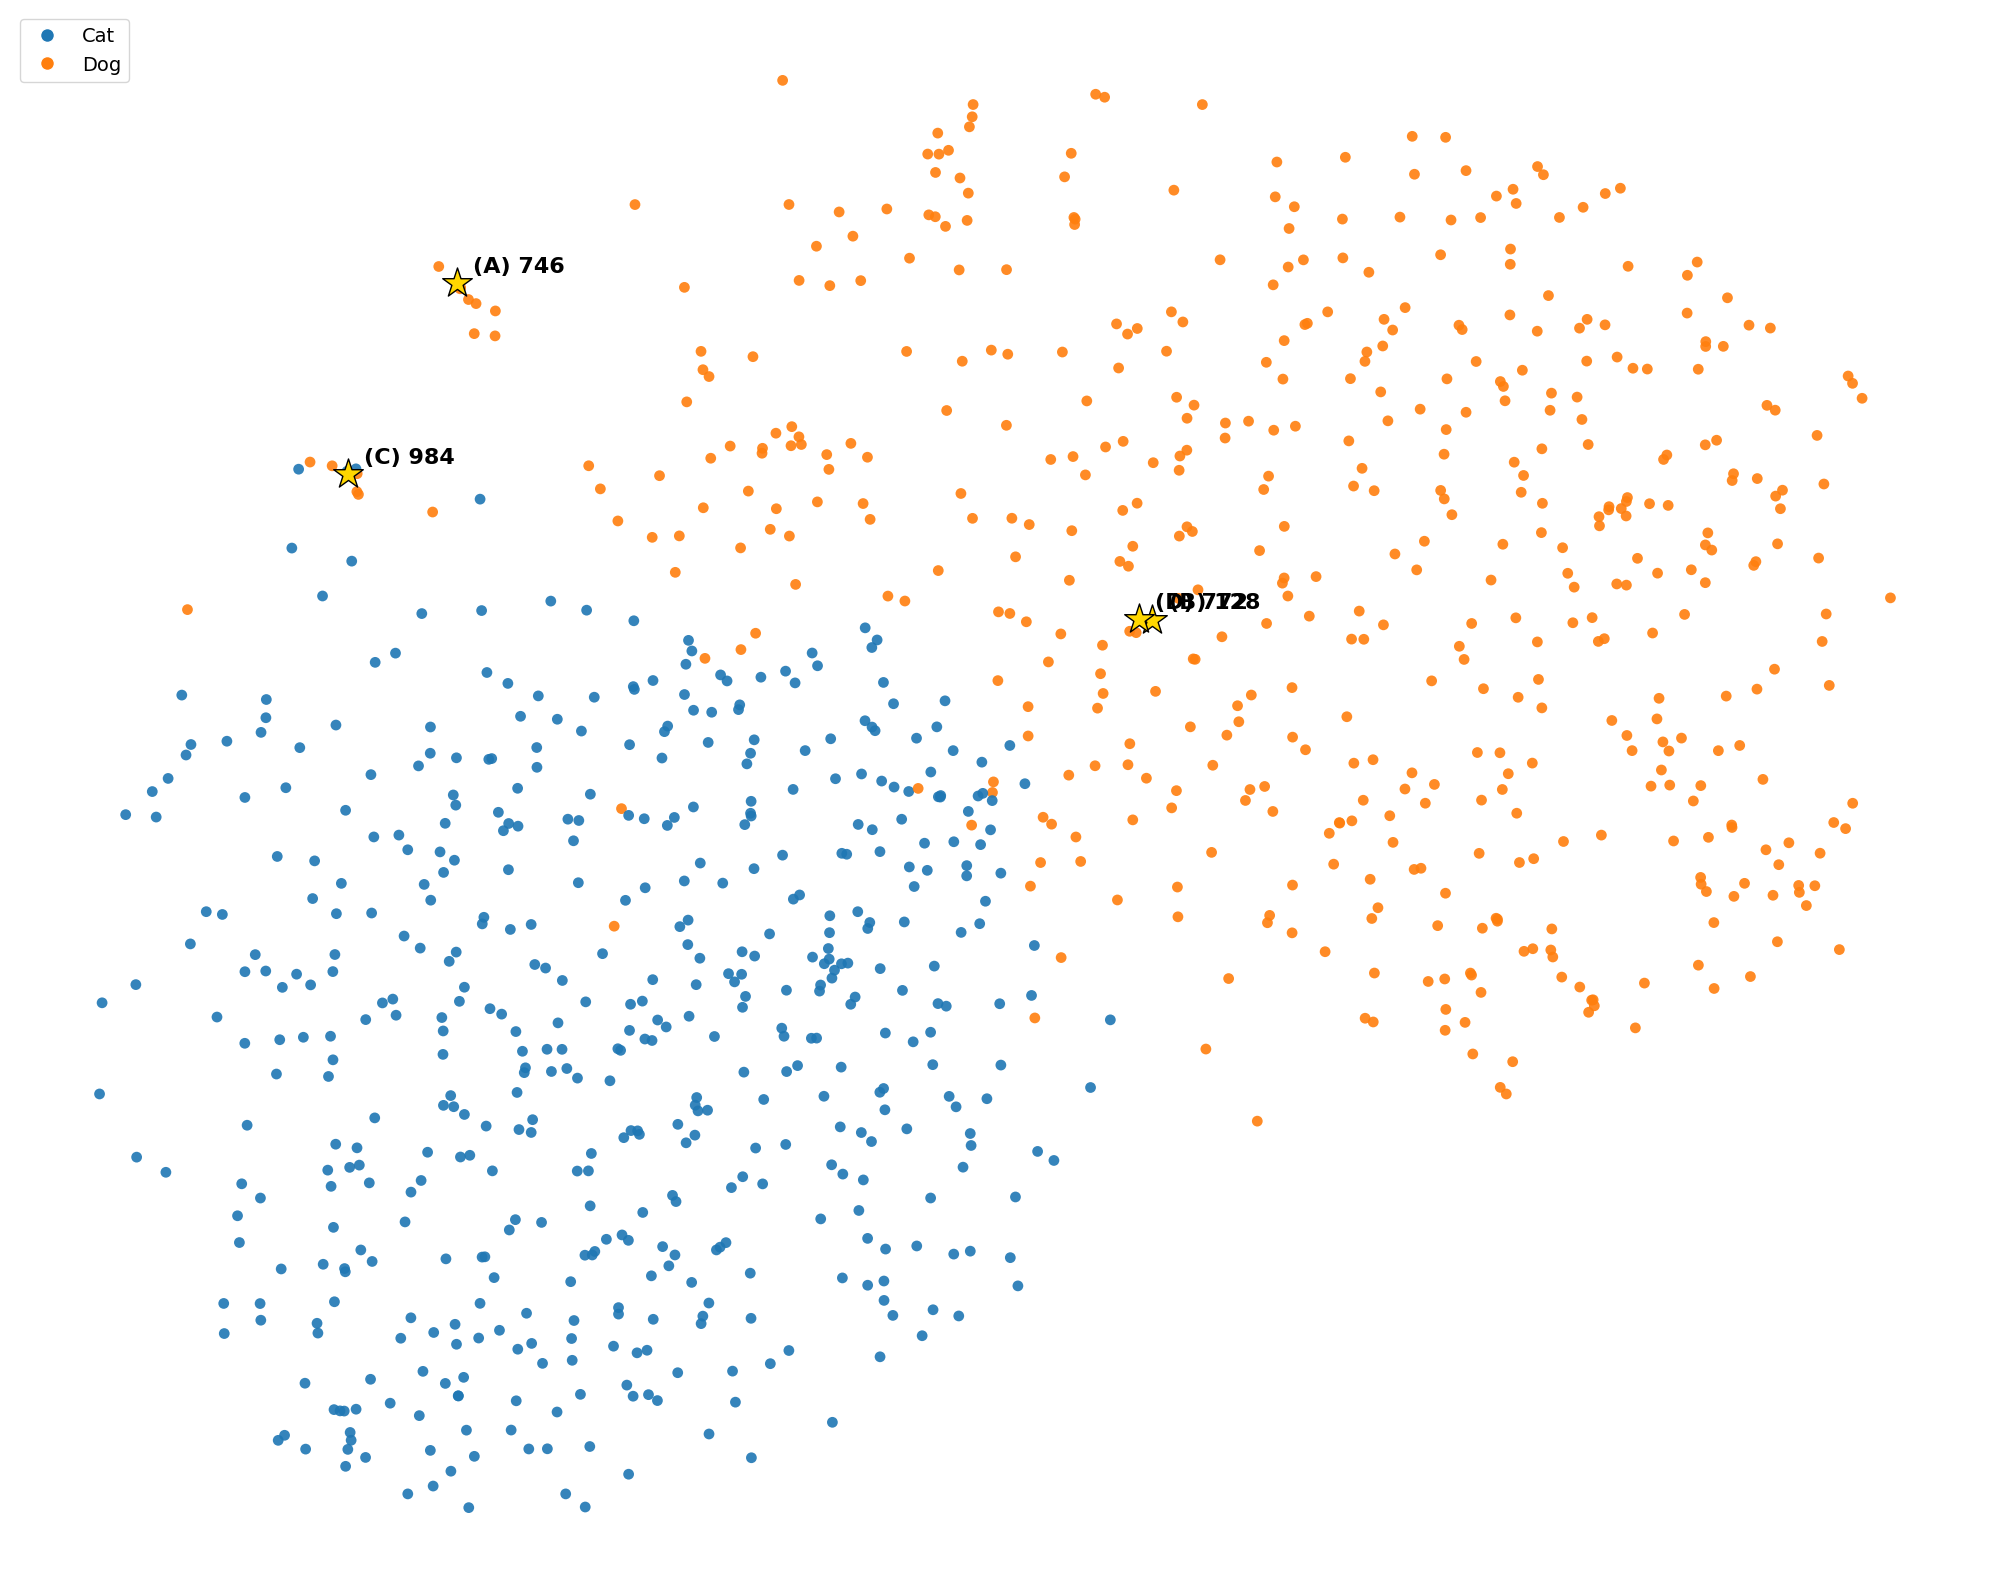

In [9]:
def tsne_plot(tsne_results, labels, highlight=None, annotate=False, figsize=(20, 16)):
    cmap = plt.get_cmap("tab10")
    class_names = np.unique(labels)                          # ['Cat', 'Dog']
    label_ids = np.searchsorted(class_names, labels)

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(tsne_results[:, 0], tsne_results[:, 1], c=label_ids, cmap=cmap, vmin=0, vmax=9,
               s=60, linewidths=0, alpha=0.9)

    if annotate:
        for i, (x, y) in enumerate(tsne_results):
            ax.annotate(str(i), (x, y), fontsize=10, ha="center", va="bottom")

    if highlight:
        for name, i in highlight.items():
            ax.scatter(*tsne_results[i], s=500, marker="*", c="gold", edgecolors="black", zorder=5)
            ax.annotate(f"({name}) {i}", tsne_results[i], xytext=(12, 8), textcoords="offset points",
                        fontsize=16, fontweight="bold")

    handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=cmap(k), markersize=10, label=n)
               for k, n in enumerate(class_names)]
    ax.legend(handles=handles, fontsize=14, loc="upper left")
    ax.axis("off")
    plt.tight_layout()
    plt.show()


tsne_plot(tsne_results, labels, highlight=FIG9_IDS)

## FADEx

In [10]:
exp = FADEx(
    high_dim_data=features,
    low_dim_data=tsne_results,
    n_neighbors=FADEX_NEIGHBORS,
    remove_const_feat=True,
    use_pca=True,          # 512 features > 50 -> local PCA (95% variance)
)

## Explanation heatmaps

For image `im_id`, the `TOP_N` features with the largest φ are selected. Their activation maps in `HEATMAP_LAYER`
are averaged, normalised to $[0, 1]$, upsampled to 224 × 224 and overlaid on the image with the `jet` colormap.

In [11]:
# Model returning the feature maps of the heatmap layer
activation_model = Model(inputs=vgg16_model.input, outputs=vgg16_model.get_layer(HEATMAP_LAYER).output)


def plot_important_features(im_id, phi, top_n=TOP_N, title=None, fname=None):
    info = orig_info[im_id]
    img = keras_image.load_img(image_path(info), target_size=IMG_SIZE)
    img_array = keras_image.img_to_array(img)

    # Activations of the heatmap layer: (14, 14, 512)
    activations = activation_model.predict(np.expand_dims(img_array, axis=0), verbose=0)[0]

    # Mean activation over the top-n FADEx features, normalised to [0, 1] and resized to 224 x 224
    important = np.argsort(phi)[-top_n:]
    heatmap = activations[:, :, important].mean(axis=-1)
    heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
    heatmap = tf.image.resize(heatmap[..., np.newaxis], IMG_SIZE).numpy().squeeze()

    image_disp = np.clip(img_array / 255.0, 0, 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(image_disp)
    axes[1].imshow(image_disp)
    axes[1].imshow(heatmap, cmap="jet", alpha=0.5)
    for ax in axes:
        ax.axis("off")
    if title:
        fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    if fname:
        fig.savefig(fname, format="pdf", dpi=300, bbox_inches="tight")
    plt.show()


def explain_image(im_id, title=None):
    phi = exp.fit(im_id, show=False)["phi"]
    info = orig_info[im_id]
    label = f"{title}  |  " if title else ""
    plot_important_features(im_id, phi, title=f"{label}id {im_id}: {info['class']} ({info['file']})",
                            fname=f"image_{im_id}.pdf" if SAVE_FIGS else None)

### Fig. 9 panels

* **(A)** and **(C)**: images from the small clusters at the top of the layout. t-SNE relies on grid and wire-fence
  features rather than on the animal.
* **(D)**: a cat placed inside the dog cluster. Leg features dominate its embedding.
* **(B)**: a nearby dog, also positioned by its leg features, which explains why it sits close to (D).

In [12]:
for panel, im_id in FIG9_IDS.items():
    explain_image(im_id, title=f"Fig. 9 ({panel})")

Output hidden; open in https://colab.research.google.com to view.

### Additional examples

Other images explored, not shown in Fig. 9.

In [13]:
for im_id in EXTRA_IDS:
    explain_image(im_id)

Output hidden; open in https://colab.research.google.com to view.